<a href="https://colab.research.google.com/github/Bhumika0104/Zomato-Restaurant-Market-Analysis/blob/main/rating_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

In [4]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
sns.set_theme()
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
#Load CSV File
try:
  from google.colab import files
  uploaded = files.upload("Zomato Restaurant Dataset.csv")
  csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
  df = pd.read_csv(csv_name)
except ImportError:
  df = pd.read_csv("Zomato Restaurant Dataset.csv")
print("Datset Loaded Successfully")
print("Rows and columns:" , df.shape)

Saving Zomato Restaurant Dataset.csv to Zomato Restaurant Dataset.csv/Zomato Restaurant Dataset.csv
Datset Loaded Successfully
Rows and columns: (9551, 21)


In [6]:
display(df.head())
print("\nDatset Infromation")
df.info()
print("\nNumerical Summary:")
display(df.describe().T)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229



Datset Infromation
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  S

,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9.051128e+06,8.791521e+06,53.000000,301962.500000,6.004089e+06,1.835229e+07,1.850065e+07
Country Code,9551.0,1.836562e+01,5.675055e+01,1.000000,1.000000,1.000000e+00,1.000000e+00,2.160000e+02
Longitude,9551.0,6.412657e+01,4.146706e+01,-157.948486,77.081343,7.719196e+01,7.728201e+01,1.748321e+02
Latitude,9551.0,2.585438e+01,1.100794e+01,-41.330428,28.478713,2.857047e+01,2.864276e+01,5.597698e+01
Average Cost for two,9551.0,1.199211e+03,1.612118e+04,0.000000,250.000000,4.000000e+02,7.000000e+02,8.000000e+05
Price range,9551.0,1.804837e+00,9.056088e-01,1.000000,1.000000,2.000000e+00,2.000000e+00,4.000000e+00
Aggregate rating,9551.0,2.666370e+00,1.516378e+00,0.000000,2.500000,3.200000e+00,3.700000e+00,4.900000e+00
Votes,9551.0,1.569097e+02,4.301691e+02,0.000000,5.000000,3.100000e+01,1.310000e+02,1.093400e+04


In [7]:
print("Missing values and columns:")
display(df.isna().sum().sort_values(ascending = False).to_frame("Missing Values"))
print("Number of duplicate rows:" , df.duplicated().sum())

Missing values and columns:


,Missing Values
Cuisines,9
Restaurant Name,0
Country Code,0
City,0
Restaurant ID,0
Address,0
Locality,0
Longitude,0
Locality Verbose,0
Latitude,0


Number of duplicate rows: 0


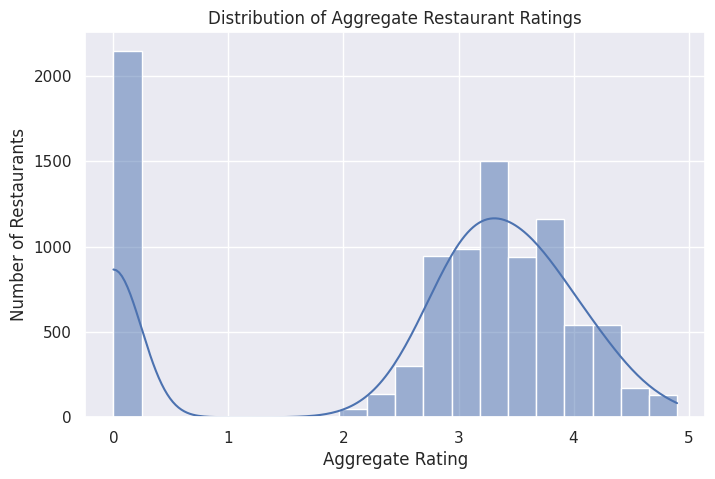

In [ ]:
#Distribution of restaurant ratings
plt.figure(figsize=(8 , 5))
sns.histplot(data=df , x="Aggregate rating" , bins = 20 , kde = True)
plt.title("Distribution of Aggregate Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.show()

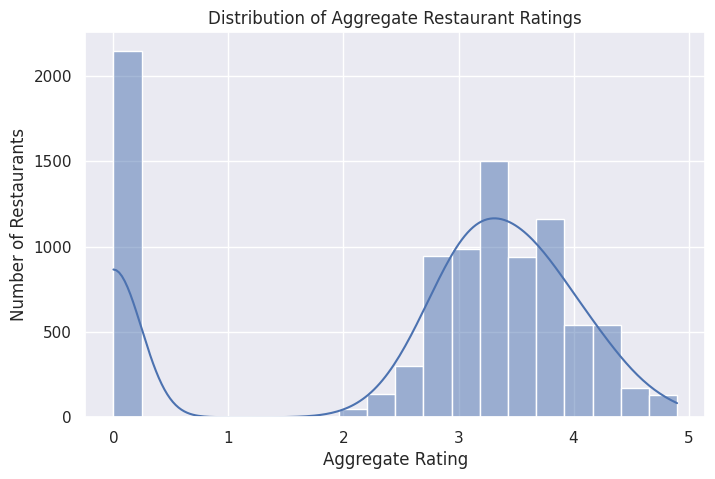

In [9]:
#Distribution of restaurant ratings
plt.figure(figsize=(8 , 5))
sns.histplot(data=df , x="Aggregate rating" , bins = 20 , kde = True)
plt.title("Distribution of Aggregate Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.show()

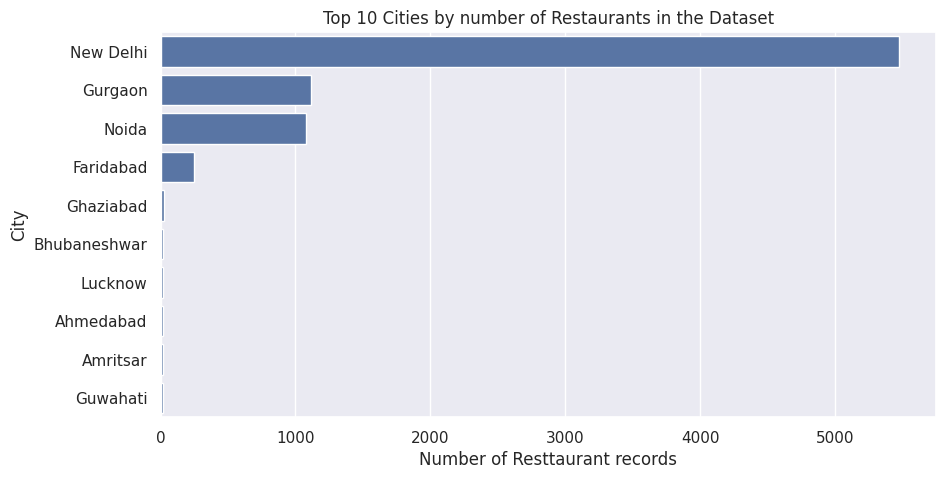

In [10]:
# Number of restaurants in the 10 cities with the most records
top_cities = df["City"].value_counts().head(10)
plt.figure(figsize= (10 , 5))
sns.barplot(x=top_cities.values , y=top_cities.index)
plt.title("Top 10 Cities by number of Restaurants in the Dataset")
plt.xlabel("Number of Resttaurant records")
plt.ylabel("City")
plt.show()

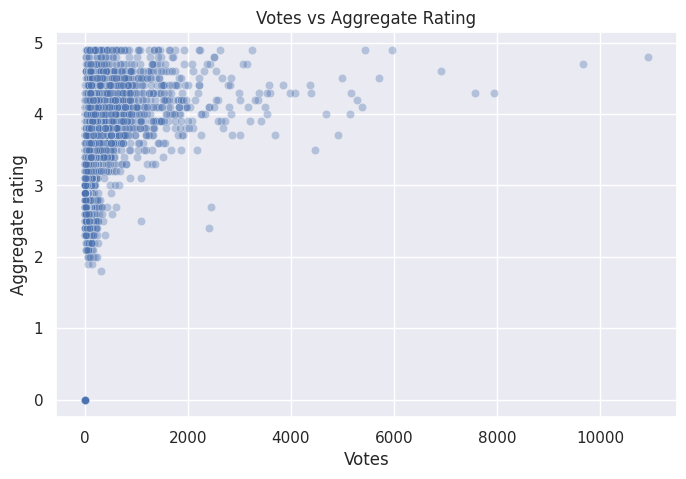

In [11]:
# Relationship between votes and rating
plt.figure(figsize=(8 , 5))
sns.scatterplot(data = df , x = "Votes" , y="Aggregate rating" , alpha = 0.35)
plt.title("Votes vs Aggregate Rating")
plt.show()

In [12]:
df_model = df.copy()
#Fill Missing cuisine labels and create a simpler cuisine feature
df_model["Cuisines"] = df_model["Cuisines"].fillna("Unknown")
df_model["Primary Cuisine"] = df_model["Cuisines"].str.split(",").str[0].str.strip()
target = "Aggregate rating"

categorical_features = ["Country Code" , "City" , "Currency" , "Has Table booking" ,
                        "Has Online delivery" , "Is delivering now" ,
                        "Switch to order menu" , "Primary Cuisine"]
numerical_features = ["Longitude" , "Latitude" , "Average Cost for two" ,
                       "Price range" , "Votes"]
feature_columns = categorical_features + numerical_features
x = df_model[feature_columns]
y = df_model[target]

print("Feature matrix shape : " , x.shape)
print("Target Shape : " , y.shape)
print("Missing values in target : " , y.isna().sum())

Feature matrix shape :  (9551, 13)
Target Shape :  (9551,)
Missing values in target :  0
